# Logistiklabb 2026

**Grupp:** Rikard & David



In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
pd.set_option("display.precision", 2)

---
# 1. Lagerstyrning och produktion
## 1a) Exponentiell utjämning

Prognosen uppdateras med

$$u(t) = a\,d(t) + (1-a)\,u(t-1), \qquad 0 \le a \le 1,$$

där $u(t-1)$ är prognosen för månad $t$ (gjord månaden innan) och $u(0)=50$ är startskattningen (prognos för januari). Prognosen för december är alltså $u(\text{nov})$.

Därefter beräknades APE (Absolute Percentage Error) för varje månad, som visar hur stort felet var mellan det verkliga och prognosiserade värdet. 

$$
\mathrm{APE}(t) = \frac{\left| d(t) - u(t-1) \right|}{d(t)} \cdot 100\,\%
$$


När felet hade beräknats för varje måndad kunde ett medelvärde (MAPE) bestämmas. 

Prognosfelet mäts med MAPE över de 11 månader där vi har utfall:

$$\text{MAPE} = \frac{100}{n}\sum_{t=1}^{n}\frac{|d(t)-u(t-1)|}{d(t)}\;\%.$$


Vikten $a$ bestämmer hur stor betydelse den senaste observationen $d(t)$ har för nästa prognos, medan $(1-a)$ är vikten för den tidigare prognosen $u(t-1)$, som bygger på alla äldre månader. Om $a = 0$ tas ingen hänsyn till förra månadens utfall, och prognosen förblir startvärdet, 50. Om $a = 1$ bygger prognosen enbart på förra månadens utfall, så nästa månads prognos blir exakt samma värde som föregående månad. 

Om $a = 0$ så kommer MAPE vara 14.0% men om $a = 1$ så kommer MAPE vara CA 20.0%. Genom att testa olika $a$ mellan 0 till 1 så kommer MAPE:n variera mellan 14-20 %.    

In [2]:
manader = ["jan","feb","mar","apr","maj","jun","jul","aug","sep","okt","nov","dec"]
d = np.array([52, 51, 60, 46, 70, 50, 39, 48, 60, 70, 60], dtype=float)
u0 = 50.0

def utjamning(a, d=d, u0=u0):
    # Returnerar prognoserna u(t-1) för jan..dec (12 värden)
    u = [u0]
    for dt in d:
        u.append(a*dt + (1-a)*u[-1])
    return np.array(u)

def mape(a):
    u = utjamning(a)
    return 100*np.mean(np.abs(d - u[:-1]) / d)

alfa = np.round(np.arange(0, 1.01, 0.1), 1)
tabell = pd.DataFrame({
    "a": alfa,
    "Prognos dec": [utjamning(a)[-1] for a in alfa],
    "MAPE (%)": [mape(a) for a in alfa],
})
tabell

,a,Prognos dec,MAPE (%)
0,0.0,50.00,14.00
1,0.1,54.15,14.45
2,0.2,56.66,14.93
3,0.3,58.48,15.26
4,0.4,59.90,15.37
5,0.5,60.94,16.20
6,0.6,61.56,17.31
7,0.7,61.74,18.29
8,0.8,61.49,19.11
9,0.9,60.89,19.79




### Härledning av den rekursiva formeln

Utgå från den viktade summan av hela tidsserien där vikterna avtar geometriskt:

$$u(t) = a\,d(t) + a(1-a)\,d(t-1) + a(1-a)^2 d(t-2) + \dots + (1-a)^t u(0)
= a\sum_{k=0}^{t-1}(1-a)^k d(t-k) + (1-a)^t u(0).$$

Skriv motsvarande uttryck för $u(t-1)$ och multiplicera med $(1-a)$:

$$(1-a)\,u(t-1) = a\sum_{k=0}^{t-2}(1-a)^{k+1} d(t-1-k) + (1-a)^t u(0) = a\sum_{k=1}^{t-1}(1-a)^{k} d(t-k) + (1-a)^t u(0).$$

Det är exakt alla termer i $u(t)$ utom den första, $a\,d(t)$. Alltså

$$u(t) = a\,d(t) + (1-a)\,u(t-1).$$

Vikterna $a(1-a)^k$ summerar (tillsammans med $(1-a)^t$) till 1, så det är ett riktigt viktat medelvärde där äldre observationer väger exponentiellt mindre.

## 1b) ABC-analys

Lagervärde per artikel = antal $\times$ medelkostnad. Artiklarna sorteras efter lagervärde och den kumulativa andelen beräknas för att göra analysen. Gränsen dras vid A = de första 80 % av värdet, B = 80-95 % och C de sista 5 %.

### Lösning i Excel

Analysen är gjord i Excel och arbetsgången är följande:

1. Lagervärdet räknas ut för varje artikel och tabellen sorteras fallande efter lagervärde.
2. Lagervärdet summeras kumulativt nedåt i tabellen.
3. Den kumulativa summan delas med det totala lagervärdet, vilket ger kumulativ andel.


| Kolumn | Innehåll | Formel (rad 3 som exempel) |
|---|---|---|
| D | Lagervärde | `=B3*C3` (antal × medelkostnad) |
| E | Kumulativt lagervärde | `=E2+D3` (i E2: `=D2`) |
| F | Kumulativ andel | `=E3/E26` (E26 = totalt lagervärde) |
| G | ABC-klass | `=OM(F3<=0,8; "A"; OM(F3<=0,95; "B"; "C"))` |

En vara klassas som A om kumulativa andelen är mindre än 80 %, B om den är mindre än 95% och annars som C.

Nedan läses Excels resultat in och formlerna hämtas direkt ur filen.

In [3]:
import openpyxl

# Värdena som Excel har räknat fram
abc = pd.read_excel("abc.xlsx", sheet_name="Blad1", header=0, usecols="A:G", nrows=25)
abc.columns = ["vara", "antal", "medelkostnad", "lagervärde", "kumulativt", "kumulativ", "klass"]
abc.index = range(1, len(abc) + 1)

# Formlerna som står i Excel-arket (rad 3 som exempel)
ws = openpyxl.load_workbook("abc.xlsx")["Blad1"]
for kol in "DEFG":
    print(f"{kol}3: {ws[f'{kol}3'].value}")

abc.style.format({"lagervärde": "{:,.0f}", "kumulativt": "{:,.0f}", "kumulativ": "{:.2%}"})

D3: =B3*C3
E3: =E2+D3
F3: =E3/$E$26
G3: =IF(F3<=0.8,"A",IF(F3<=0.95,"B","C"))


,vara,antal,medelkostnad,lagervärde,kumulativt,kumulativ,klass
1,15,84000,30,"2,520,000","2,520,000",39.91%,A
2,19,21770,35,"761,950","3,281,950",51.98%,A
3,13,1306,500,"653,000","3,934,950",62.32%,A
4,3,70000,5,"350,000","4,284,950",67.87%,A
5,10,19593,13,"254,709","4,539,659",71.90%,A
6,1,700,342,"239,400","4,779,059",75.69%,A
7,9,10500,21,"220,500","4,999,559",79.18%,A
8,4,68000,3,"204,000","5,203,559",82.42%,B
9,12,19593,10,"195,930","5,399,489",85.52%,B
10,2,800,200,"160,000","5,559,489",88.05%,B


In [4]:
sammanfattning = abc.groupby("klass").agg(
    antal_artiklar=("vara", "count"),
    lagervärde=("lagervärde", "sum"),
)
sammanfattning["andel artiklar (%)"] = 100 * sammanfattning["antal_artiklar"] / len(abc)
sammanfattning["andel lagervärde (%)"] = 100 * sammanfattning["lagervärde"] / abc["lagervärde"].sum()
sammanfattning

,antal_artiklar,lagervärde,andel artiklar (%),andel lagervärde (%)
klass,,,,
A,7,4999559,28.0,79.18
B,7,996852,28.0,15.79
C,11,317420,44.0,5.03



Det blev 7 A-artiklar som står för ca 79% av hela lagervärdet. Vilket kommer att innebära tät uppföljning, noggranna prognoser och beställningspunkter för just dessa varor. B och speciellt C-artiklar klarar sig med enkla regler, större partier och mindre kontroll.

Här ser vi det illustrerat hur

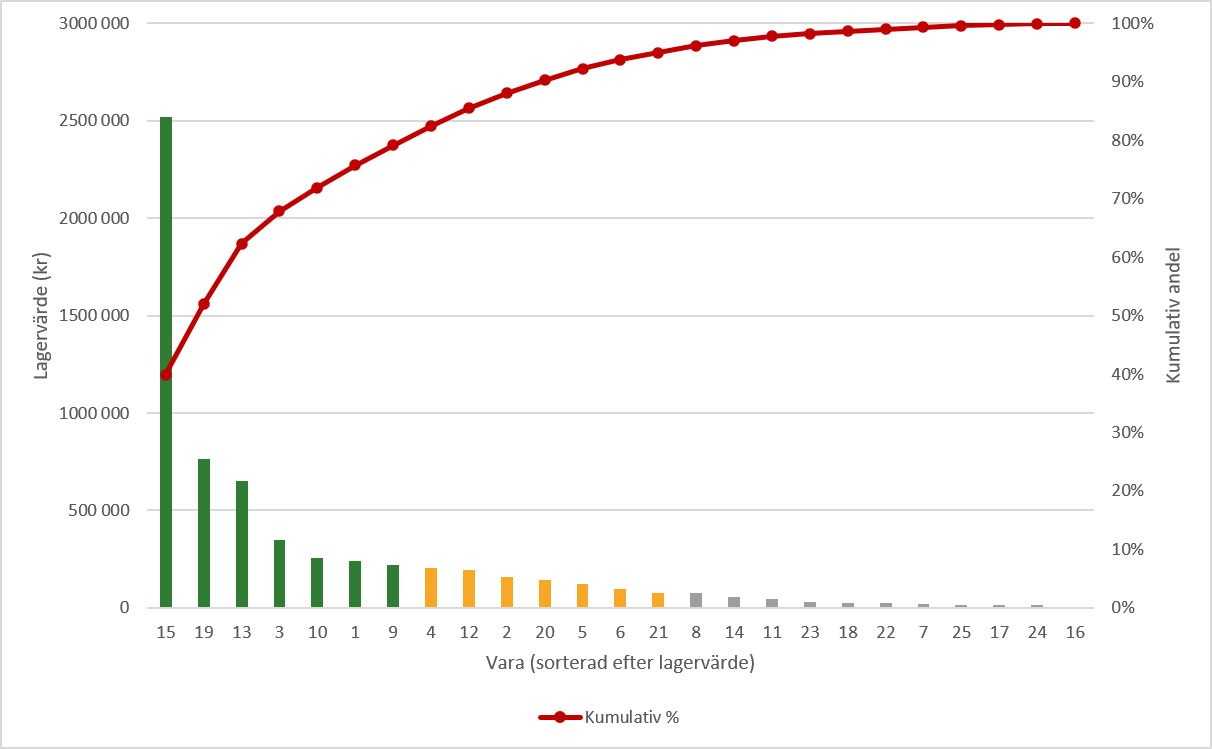

---
# 2. Heltalsprogrammering 

I denna uppgift ska fyra arbetare genomföra sex olika arbetsuppgifter. Varje arbetsuppgift kan endast utföras av en arbetare. Arbetarena utför uppgifterna med olika arbetstider och har dessutom olika många tillgängliga arbetsdagar. Person 1 behöver två dagar för att utföra en uppgift, person 2 och 3 behöver tre dagar verdera, medan person 4 behöver fyra dagar. 


**Målfunktionen**

Målet att hitta den optimala lösningen där rätt person genomför rätt arbetsuppgift för att maximera den totala vinsten. Målfunktionen skrivs därför som: 


$$
\max Z = \sum_{i=1}^{4}\sum_{j=1}^{6} V_{ij}x_{ij}
$$


**Bivillkor**

Det finns två olika bivillkor i uppgiften. 

Det första bivvilkoret begränsar arbetarnas arbetstid. Varje arbetare har ett begränsat antal tillgängliga arbtesdagar. 

För arbetare 1 :

$$
2\sum_{j=1}^{6}x_{1j}\leq 4
$$


För arbetare 2 :

$$
3\sum_{j=1}^{6}x_{2j}\leq 4
$$


För arbetare 3 :

$$
3\sum_{j=1}^{6}x_{3j}\leq 8
$$

För arbetare 4 : 

$$
4\sum_{j=1}^{6}x_{4j}\leq 8
$$

Det andra bivillkoret innebär att varje arbetsuppgift måste tilldelas exakt en arbetare. Därför måste summan av varje kolumn i beslutsmatrisen vara lika med ett. 


$$
\sum_{i=1}^{4}x_{ij}=1,
\quad j=1,\ldots,6
$$

Slutligen så är beslutsvariabel binär, vilket innebär att de endast kan vara 0 eller 1. 

### 2a) Modell och lösning





In [ ]:
V = np.array([[37000, 23000, 20000, 18000, 16000, 6000],
     [25000, 14000, 14000, 18000, 17000, 8000],
     [5000,  13000, 10000, 12000,  5000, 5000],
     [10000,  3000, 13000,  7000,  2000, 16000]
     ])

dagar = [2, 3, 3, 4]
tid = [4,4,8,8]

obj = -V.flatten()

x = np.zeros((4, 6))




print(losa([4, 4, 8, 8]))   # a)
print(losa([6, 4, 8, 8]))   # b)

NameError: name 'losa' is not defined

---
# 3. Omlastningsmodell: probabilistiska bivillkor och heltal

### 3a) Nätverk och definitioner
### 3b) Generell modell
### 3c) Lösning med medelefterfrågan
### 3d) Probabilistiska bivillkor (90 %)
### 3e) Fasta kostnader för bruken
### 3f) Kapacitet på länkarna och heltal

---
# 4. Intermodal transportplanering

### 4a) Generell modell
### 4b) En färja (2000 lastbilar/år)
### 4c) Fler färjor
### 4d) Minskad kapacitet på vägen 2–3

---
# 5. Tomma godsvagnar

### 5a) Nätverk och modelltyp
### 5b) Generell modell
### 5c) Lösning
### 5d) Med och utan trängselvillkor
### 5e) Känslighet för P